In [ ]:
import pandas as pd
from astropy.io.votable import parse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# functions taken from the explorer
from explorer.fitting import fit_dr4_like_single_source # is a look up function for the best fit parameters of each source.
from explorer.normalize import normalize_epoch_astrometry # see below

# The normalize_epoch_astrometry function, transforms the data into a convinient tabulated data set for plotting and computing model values.
# e.g. instead of using the time of observation in nanoseconds it gives you the time in years relative to a reference time (J2017.5).

In [ ]:
votable = parse("prerelease_DR4_test/GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml")
table = votable.get_first_table().to_table()

In [41]:
# Get all unique source IDs from the VOTable
source_ids = np.unique(np.asarray(table["source_id"], dtype=np.int64))

# Create readable labels
source_labels = {
    sid: f"Source {i + 1}: {sid}"
    for i, sid in enumerate(source_ids)
}

for label in source_labels.values():
    print(label)

Source 1: 2237987199365376
Source 2: 2309425390592896
Source 3: 10973744521070720
Source 4: 20694084440761600
Source 5: 60730287810150016
Source 6: 435469040545191680
Source 7: 1457486023639239296
Source 8: 1663617687609809280
Source 9: 3926186255616949504
Source 10: 3937211745905473024
Source 11: 4181040337841125632
Source 12: 4318465066420528000


In [ ]:
source_id = 2237987199365376

# Keep the published transit rows as an Astropy table and normalize them once.
source_table = table[table["source_id"] == source_id]  # table comes form VOTable 
normalized = normalize_epoch_astrometry(source_table) # gives you a nice data frames
ccd = normalized.ccd # convinient table for plotting all CCD centroid_pos_al

# The normalized table preserves the published CCD ordering and broadcasts
# transit-level quantities to the corresponding ten CCD observations.
def ccd_float(column_name):
    return np.asarray(np.ma.filled(ccd[column_name], np.nan), dtype=float)

# pull data from the normalised table 
centroid_pos_al = ccd_float("centroid_pos_al")
centroid_obs_error = ccd_float("centroid_pos_error_al")
scan_model_deg = ccd_float("scan_pos_angle")
time_model_year = ccd_float("relative_time_year")
parallax_factor_model = ccd_float("parallax_factor_al")
colour_factor_raw = ccd_float("colour_factor_al")
used_model = np.asarray(
    np.ma.filled(ccd["used_by_agis_al"], False),
    dtype=bool,
)

# gaiasupdate converts the archive colour factor before fitting.
colour_factor_model = -1e3 * colour_factor_raw

# Apply the same finite-data requirements as the model calculation. This is
# Boolean filtering; multiplying by the mask would create artificial zeros.
model_mask = (
    used_model
    & np.isfinite(centroid_pos_al)
    & np.isfinite(scan_model_deg)
    & np.isfinite(time_model_year)
    & np.isfinite(parallax_factor_model)
    & np.isfinite(colour_factor_model)
)

if not np.any(model_mask):
    raise ValueError("No finite AGIS-used CCD observations are available.")

fit_result = fit_dr4_like_single_source(table, source_id)   
parameters = dict(
    zip(fit_result.parameter_names, fit_result.parameters, strict=True)
)

theta_model = np.deg2rad(scan_model_deg[model_mask]) # scan angle comes in degrees
t_model = time_model_year[model_mask]

model_centroid_al = (
    parameters["delta_alpha_star"] * np.sin(theta_model)
    + parameters["delta_delta"] * np.cos(theta_model)
    + parameters["parallax"] * parallax_factor_model[model_mask]
    + parameters["pmra_star"] * t_model * np.sin(theta_model)
    + parameters["pmdec"] * t_model * np.cos(theta_model)
    + parameters["pseudocolour_term"] * colour_factor_model[model_mask]
)

observed_centroid_al = centroid_pos_al[model_mask]
manual_residuals = observed_centroid_al - model_centroid_al

print(f"CCD slots: {len(ccd)}")
print(f"AGIS-used finite CCD observations: {model_mask.sum()}")
print(f"Official fit measurements: {fit_result.n_measurements}")
print(f"Manual residual RMS: {np.sqrt(np.mean(manual_residuals**2)):.6f} mas")
print(f"Official residual RMS: {np.sqrt(np.mean(fit_result.residuals**2)):.6f} mas")

# This is the definitive alignment check: the manual model must reproduce
# the residuals returned by gaiasupdate, not merely resemble the data plot.
if model_mask.sum() != len(fit_result.residuals):
    raise ValueError(
        "The normalized CCD mask does not match the observations retained by "
        f"the fit ({model_mask.sum()} versus {len(fit_result.residuals)})."
    )

max_residual_difference = np.max(
    np.abs(manual_residuals - fit_result.residuals)
)
print(f"Maximum manual/official residual difference: {max_residual_difference:.3e} mas")

if not np.allclose(manual_residuals, fit_result.residuals, rtol=0.0, atol=1e-7):
    raise ValueError(
        "The manually reconstructed model does not reproduce the official fit."
    )


CCD slots: 880
AGIS-used finite CCD observations: 702
Official fit measurements: 702
Manual residual RMS: 3.975862 mas
Official residual RMS: 3.975862 mas
Maximum manual/official residual difference: 2.007e-13 mas


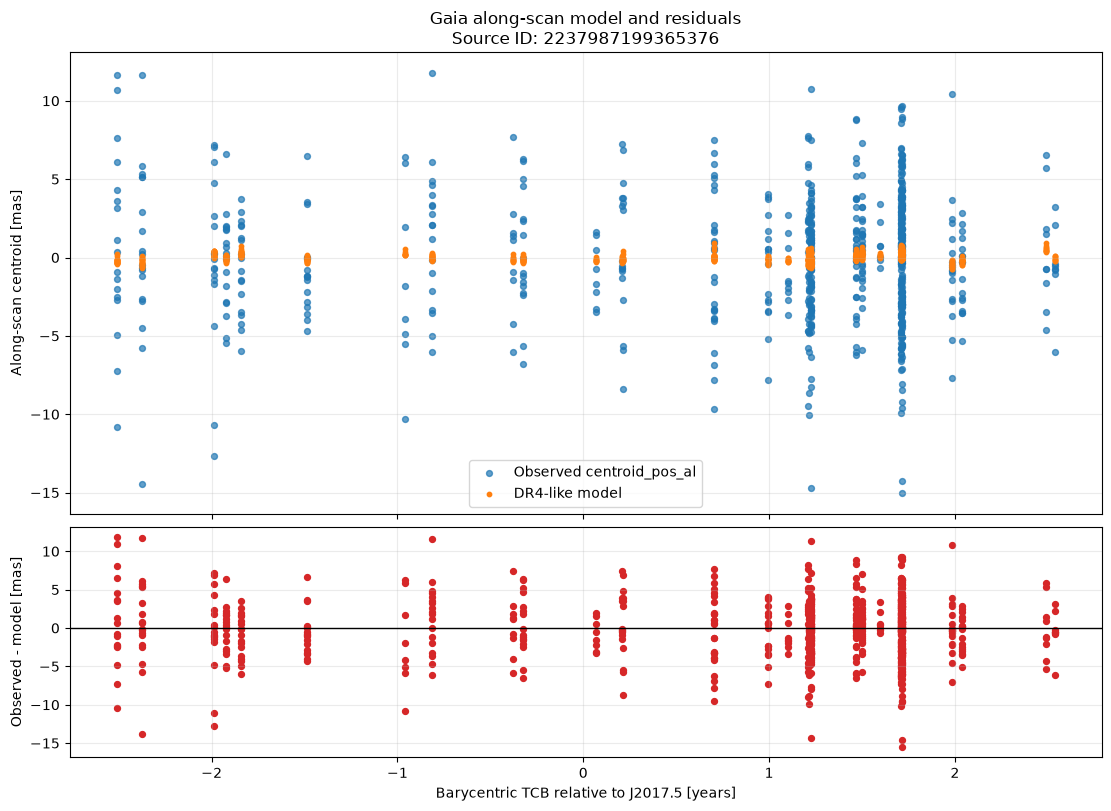

In [44]:
order = np.argsort(t_model)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": (2, 1)},
)

axes[0].scatter(
    t_model[order],
    observed_centroid_al[order],
    s=18,
    alpha=0.7,
    color="tab:blue",
    label="Observed centroid_pos_al",
)
axes[0].scatter(
    t_model[order],
    model_centroid_al[order],
    s=10,
    color="tab:orange",
    label="DR4-like model",
)
axes[0].set_ylabel("Along-scan centroid [mas]")
axes[0].set_title(f"Gaia along-scan model and residuals\nSource ID: {source_id}")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].scatter(
    t_model[order],
    manual_residuals[order],
    s=18,
    color="tab:red",
)
axes[1].set_xlabel("Barycentric TCB relative to J2017.5 [years]")
axes[1].set_ylabel("Observed - model [mas]")
axes[1].grid(True, alpha=0.25)

plt.show()


In [42]:
display(ccd)

ccd_index,ccd_name,obs_time_tcb,scan_pos_angle,colour_factor_al,colour_factor_ac,centroid_pos_al,calculated_pos_ac,centroid_pos_error_al,used_by_agis_al,used_by_agis_ac,ccd_proc_flags,ipd_error_al,ipd_error_ac,gates,source_dist_to_last_ci,sub_pixel_coord,mu,solution_id,source_id,transit_id,ra0,dec0,agis_source_excess_noise,obs_time_bary_corr,zeta,parallax_factor_al,parallax_factor_ac,nu_eff_used_in_astrometry,nu_eff_error,transit_acq_flags,transit_proc_flags,multipeak,blended,g_mag,g_class,ac_rate,centroid_pos_ac,centroid_pos_error_ac,fov,obs_time_jd_tcb,obs_time_jyear_tcb,obs_time_jd_tcb_barycentric,relative_time_year
,,ns,deg,,,mas,mas,mas,,,,mas,mas,,pix,pix,pix,,,,deg,deg,mas,ns,deg,,,1 / um,1 / um,,,,,mag,,pix / s,mas,mas,,d,yr,d,yr
int8,str3,int64,float64,float32,float32,float64,float64,float32,bool,bool,uint16,float32,float32,uint16,float32,float32,float32,int64,int64,int64,float64,float64,float32,float32,float32,float32,float32,float32,float32,uint16,uint16,bool,bool,float32,int16,float32,float64,float64,int64,float64,float64,float64,float64
0,SM,161720874396079379,-57.65601007857511,6.220978,3.8766282,8.179439681639142,-88.89485638527994,15.014283,False,False,512,15.015751,44.0167,12,--,0.3869171,1450.0,2888461026632663040,2237987199365376,26261503312803252,44.85905323725608,4.4936838241186345,0.0,-105902916000.0,0.06135436,0.6695347,0.7042291,1.4384817,0.022273893,8240,564,False,False,19.754549,3,0.9695335,--,--,0,2457069.269379584,2015.1246252692245,2457069.268153856,-2.375378086636374
1,AF1,161720884310443598,-57.656102855710984,5.9781394,--,5.154754374512048,0.3931927174428818,4.8111744,True,False,8192,4.6408615,--,0,1136.8972,0.26245117,1460.0,2888461026632663040,2237987199365376,26261503312803252,44.85905323725608,4.4936838241186345,0.0,-105902916000.0,0.06135436,0.6695347,0.7042291,1.4384817,0.022273893,8240,564,False,False,19.754549,3,0.9695335,--,--,0,2457069.269494334,2015.1246255833917,2457069.2682686057,-2.375377772468937
2,AF2,161720889166135946,-57.656148336374265,4.908106,--,-0.7765482895696278,0.3931927177130142,2.6993423,True,False,0,2.6541631,--,0,395.5691,0.934288,1465.0,2888461026632663040,2237987199365376,26261503312803252,44.85905323725608,4.4936838241186345,0.0,-105902916000.0,0.06135436,0.6695347,0.7042291,1.4384817,0.022273893,8240,564,False,False,19.754549,3,0.9695335,--,--,0,2457069.269550534,2015.1246257372593,2457069.268324806,-2.3753776186013056
3,AF3,161720894026185212,-57.65619389754549,3.06078,--,2.8778216016141327,0.39319288020105553,2.587594,True,False,0,2.5860543,--,0,1650.6741,0.039283752,1470.0,2888461026632663040,2237987199365376,26261503312803252,44.85905323725608,4.4936838241186345,0.0,-105902916000.0,0.06135436,0.6695347,0.7042291,1.4384817,0.022273893,8240,564,False,False,19.754549,3,0.9695335,--,--,0,2457069.2696067845,2015.124625891265,2457069.2683810564,-2.3753774645958856
4,AF4,161720898886021738,-57.65623950575473,2.729087,--,-2.7935865142738625,0.3931928866257288,2.6741471,True,False,0,2.662883,--,0,905.5626,0.9278259,1475.0,2888461026632663040,2237987199365376,26261503312803252,44.85905323725608,4.4936838241186345,0.0,-105902916000.0,0.06135436,0.6695347,0.7042291,1.4384817,0.022273893,8240,564,False,False,19.754549,3,0.9695335,--,--,0,2457069.2696630326,2015.124626045264,2457069.2684373045,-2.375377310596832
5,AF5,161720903746084097,-57.656285174663715,1.8513311,--,-1.1824360565295409,0.3931929875974189,2.4932137,True,False,0,2.4934573,--,0,160.68094,0.046142578,1479.0,2888461026632663040,2237987199365376,26261503312803252,44.85905323725608,4.4936838241186345,0.0,-105902916000.0,0.06135436,0.6695347,0.7042291,1.4384817,0.022273893,8240,564,False,False,19.754549,3,0.9695335,--,--,0,2457069.2697192836,2015.12462619927,2457069.268493555,-2.375377156591412
6,AF6,161720908605687154,-57.65633090140144,0.58982164,--,0.4107242484116812,0.3931931108385867,2.6212096,True,False,0,2.621466,--,0,1415.3319,0.6971283,1484.0,2888461026632663040,2237987199365376,26261503312803252,44.8

# Ignore bellow, old code probably worth deleting (keeping for now)

In [22]:
# votable = parse("prerelease_DR4_test/GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml")
# table = votable.get_first_table().to_table()

In [23]:
# # Choosing the BH3 source since its a nice example
# source_id = 4318465066420528000 # BH3
# # source = table[table["source_id"] == source_id]
# # From astropy type to pandas data frame
# df = table.to_pandas()
# source = df[df["source_id"] == source_id]

In [24]:
# def numeric_array(series):
#     return np.asarray(
#         [
#             [
#                 np.nan if value is None or str(value) == "--" else float(value)
#                 for value in row
#             ]
#             for row in series
#         ],
#         dtype=float,
#     )

# def al_scan_direction(scan_pos_angle):
#     """
#     Return the unit vector along the Gaia along-scan direction.

#     Parameters
#     ----------
#     scan_pos_angle : array-like
#         Scan position angle in degrees.

#     Returns
#     -------
#     ux, uy : ndarray
#         Components of the AL unit vector in the sky plane:

#         ux = sin(theta)
#         uy = cos(theta)
#     """
#     theta = np.deg2rad(scan_pos_angle, dtype=float)

#     return np.sin(theta), np.cos(theta)

In [25]:
# scan = numeric_array(source['scan_pos_angle'])
# centroid_al = numeric_array(source['centroid_pos_al'])
# centroid_al_error = numeric_array(source['centroid_pos_error_al'])
# centroid_ac = numeric_array(source['calculated_pos_ac'])
# obs_times_tcb = numeric_array(source["obs_time_tcb"])
# used_by_agis_al = numeric_array(source['used_by_agis_al'])
# parallax_factor_al = np.asarray(source['parallax_factor_al'])
# colour_factor_al =  numeric_array(source['colour_factor_al'])

In [26]:
# reject = True

# t_rel_year = (obs_times_tcb - obs_times_tcb.min()) / (
#     365.25 * 86400 * 1e9
# )

# if reject == True:
#     centroid_al_data = centroid_al * used_by_agis_al
#     time_years_data = t_rel_year * used_by_agis_al


In [27]:
# # Flatten the per-transit/per-sample arrays and keep only valid AGIS-used samples
# x = t_rel_year.ravel()
# y = centroid_al.ravel()
# used = used_by_agis_al.ravel()

# valid = (
#     (used != 0)
#     & np.isfinite(x)
#     & np.isfinite(y)
# )

# fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)

# ax.scatter(
#     x[valid],
#     y[valid],
#     s=20,
#     alpha=0.75,
#     color="tab:blue",
#     edgecolors="white",
#     linewidths=0.3,
#     rasterized=True,
# )

# ax.set_title(f"Gaia AL centroid measurements\nSource ID: {source_id}")
# ax.set_xlabel("Time since first observation [years]")
# ax.set_ylabel("Along-scan centroid")
# ax.grid(True, alpha=0.25)
# ax.ticklabel_format(axis="x", style="plain")

# plt.show()

## I want to plot the model (of centroid pos) vs obs time

In [28]:
# from casty.fitting import fit_dr4_like_single_source


In [29]:
# import sys
# import gaiasupdate

# fit_result = fit_dr4_like_single_source(table, source_id,)

In [30]:
# print(fit_result.model)
# print(fit_result.parameter_names)
# print(fit_result.parameters)
# print(fit_result.parameter_errors)
# print(fit_result.n_measurements)

In [31]:
# parameter_values = dict(
#     zip(
#         fit_result.parameter_names,
#         fit_result.parameters,
#         strict=True,
#     )
# )

# parameter_values

In [32]:
# scan_flat = scan.flatten()
# centroid_al_flat = centroid_al.flatten()
# centroid_al_error_flat = centroid_al_error.flatten()
# used_by_agis_al_flat = used_by_agis_al.flatten()
# parallax_factor_al_flat = parallax_factor_al.flatten()
# t_rel_year_flat = t_rel_year.flatten()

In [33]:
# parameter_values = dict(
#     zip(
#         fit_result.parameter_names,
#         fit_result.parameters,
#         strict=True,
#     )
# )

# delta_alpha_star = parameter_values["delta_alpha_star"]
# delta_delta = parameter_values["delta_delta"]
# parallax = parameter_values["parallax"]
# pmra_star = parameter_values["pmra_star"]
# pmdec = parameter_values["pmdec"]
# pseudocolour_term = parameter_values["pseudocolour_term"]

In [34]:
# s, c = al_scan_direction(scan)

# # model_centroid_al = (
# #     delta_alpha_star * s
# #     + delta_delta * c
# #     + parallax * parallax_factor_al
# #     + pmra_star * t_rel_year * s
# #     + pmdec * t_rel_year * c
# #     #+ pseudocolour_term * colour_factor_al
# # )

In [35]:
# parallax_factor_al = np.broadcast_to(
#     np.asarray(parallax_factor_al)[:, None],
#     (77,10),
# )

# # colour_factor_al_reshaped = np.broadcast_to(
# #     np.asarray(colour_factor_al)[:, None],
# #     (77,10),
# # )


# variables = {
#     "delta_alpha_star": delta_alpha_star,
#     "s": s,
#     "delta_delta": delta_delta,
#     "c": c,
#     "parallax": parallax,
#     "parallax_factor_al": parallax_factor_al,
#     "pmra_star": pmra_star,
#     "t_rel_year": t_rel_year,
#     "pmdec": pmdec,
#     "colour_factor_al": colour_factor_al
# }

# for name, value in variables.items():
#     print(f"{name:20s}: {np.shape(value)}")


# # Expand the one-value-per-transit parallax factor to one value per sample.



# model_centroid_al = (
#     delta_alpha_star * s
#     + delta_delta * c
#     + parallax * parallax_factor_al
#     + pmra_star * t_rel_year * s
#     + pmdec * t_rel_year * c
#     + pseudocolour_term * colour_factor_al
# )

# # print(model_centroid_al.shape)
# # print((model_centroid_al[0]))

In [36]:
# t = t_rel_year.flatten()
# y_model = model_centroid_al.flatten()
# y_obs = centroid_al.flatten()
# print(t.shape, y_model.shape, y_obs.shape)
# plt.scatter(t, y_model)
# plt.scatter(t, y_obs)
# print(y_model[769])

In [37]:
# # Flatten the 77 x 10 arrays for plotting
# time_flat = np.asarray(t_rel_year).ravel()
# model_flat = np.asarray(model_centroid_al).ravel()
# measured_flat = np.asarray(centroid_al).ravel()
# used_flat = np.asarray(used_by_agis_al).ravel()

# valid_model = (
#     (used_flat != 0)
#     & np.isfinite(time_flat)
#     & np.isfinite(model_flat)
# )

# valid_measured = (
#     (used_flat != 0)
#     & np.isfinite(time_flat)
#     & np.isfinite(measured_flat)
# )

# model_order = np.argsort(time_flat[valid_model])

# fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)

# ax.scatter(
#     time_flat[valid_model][model_order],
#     model_flat[valid_model][model_order],
#     s=8,
#     color="tab:orange",
#     label="Model",
# )

# ax.scatter(
#     time_flat[valid_measured],
#     measured_flat[valid_measured],
#     s=20,
#     alpha=0.75,
#     color="tab:blue",
#     edgecolors="white",
#     linewidths=0.3,
#     label="Measured",
# )

# ax.set_title(f"Model and measured AL centroid positions\nSource ID: {source_id}")
# ax.set_xlabel("Time since first observation [years]")
# ax.set_ylabel("Along-scan centroid")
# ax.grid(True, alpha=0.25)
# ax.ticklabel_format(axis="x", style="plain")
# ax.legend()

# plt.show()

## Corrected

The issue with the above is that I used the wrong time comp
